In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import random
import fastplotlib as fpl

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.
WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


Incompatible version of wgpu:
    Detected 0.15.3.post97+g8a0b267, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: float,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.005,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: float

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [63]:
k = 10

In [64]:
X, _ = generate_data(
    n_timepoints=5_000,
    n_components=k,
    noise=0.1,
    n_pixels=5,
    n_pixels_bg=0,
    interp_factor=1,
    firing_prop=0.1,
)

In [65]:
X_init = X[:, :200]

<Axes: >

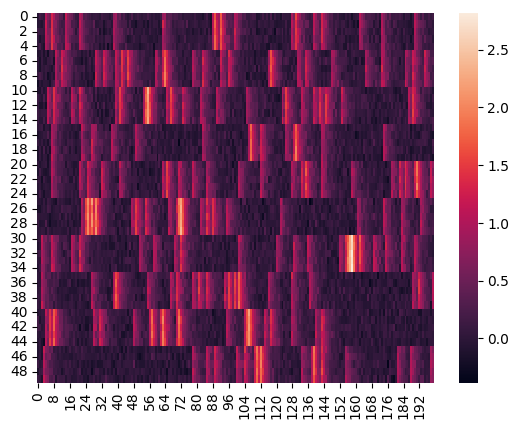

In [66]:
sns.heatmap(X_init)

In [67]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [68]:
convergence = False
etamax = 1e-1
eta = etamax

scounter = 1

In [69]:
from tqdm.notebook import tqdm

In [77]:
# Ys = list()

Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)
# Y, _ = generate_data(
#     n_timepoints=200,
#     n_components=k,
#     noise=0.7,
#     n_pixels=1,
#     n_pixels_bg=0,
#     interp_factor=1,
#     firing_prop=0.1,
# )

Y /= Y.max()
Y *= X.max()

for iteration in tqdm(range(1_000_000)):
    # Ys.append(Y)
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)
    
    zeroed = Y.sum(axis=1) == 0.0
    Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
    
    Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta

    if er < 1e-3:
        convergence = True
        break

  0%|          | 0/1000000 [00:00<?, ?it/s]

# rendercanvas to update F and show error line plot in for loop

In [78]:
er

np.float64(0.0009241002891697042)

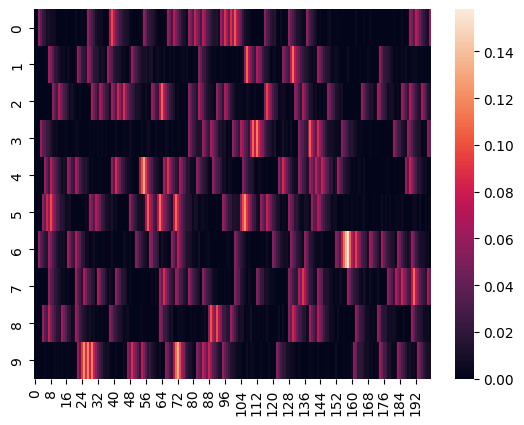

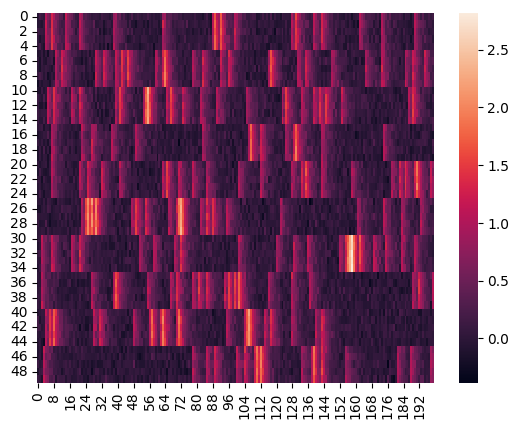

In [79]:
sns.heatmap(Y[:, :200])
plt.show()

sns.heatmap(X_init[:, :200])
plt.show()

<Axes: >

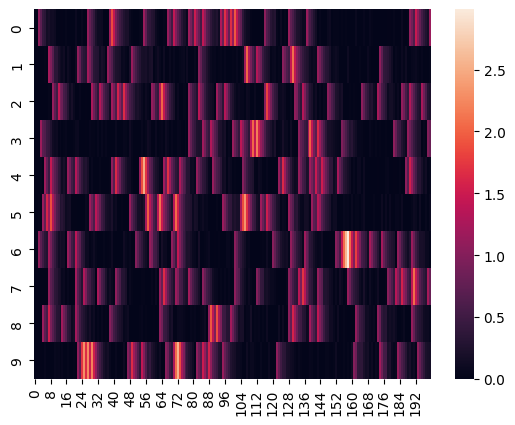

In [80]:
Y2 = Y.copy()
Y2 /= Y2.max()
Y2 *= X.max()
sns.heatmap(Y2)

In [81]:
sum_y_squared = np.square(Y).sum(axis=1)[:, None]
sum_y_squared.shape

(10, 1)

In [82]:
W = Y @ X_init.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [83]:
W.shape

(10, 50)

In [84]:
Y.shape

(10, 200)

<Axes: >

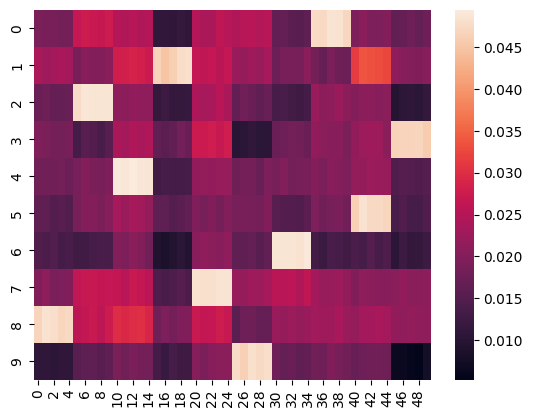

In [85]:
sns.heatmap(W / np.square(Y2).sum(axis=1)[:, None])

<Axes: >

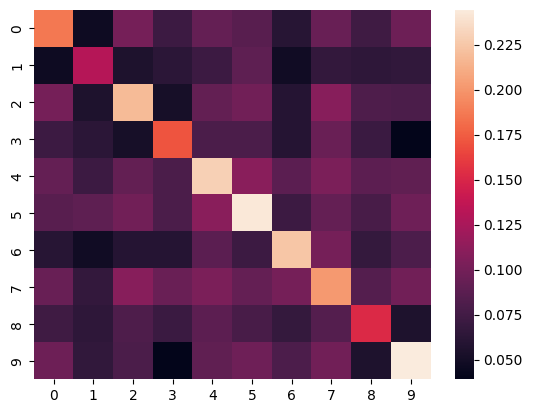

In [86]:
sns.heatmap(M)

In [99]:
np.linalg.eigvals(M)

array([0.9244764 , 0.18192522, 0.17722908, 0.15550516, 0.06108684,
       0.06632421, 0.08802791, 0.09790697, 0.12556334, 0.12211787])

In [100]:
F = np.linalg.inv(M) @ W

In [101]:
F /= F.sum(axis=1)[:, None]

In [102]:
F[0].sum()

np.float64(1.0000000000000002)

<Axes: >

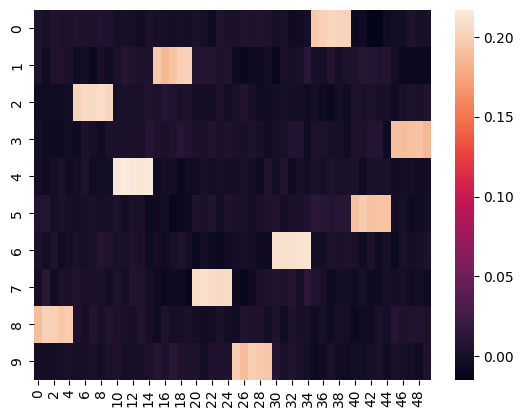

In [103]:
sns.heatmap(F)

<Axes: >

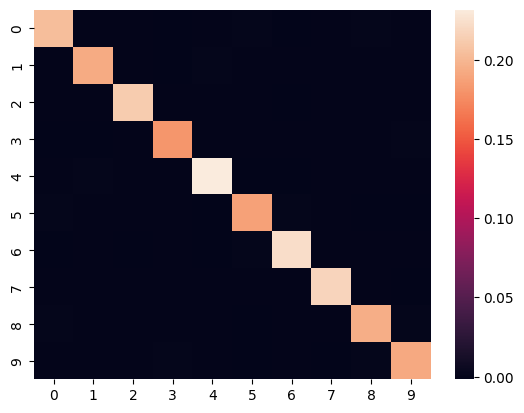

In [166]:
sns.heatmap(F @ F.T)

In [144]:
F.argmax(axis=0)

array([8, 8, 8, 8, 8, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 1, 1, 1, 1, 1, 7, 7,
       7, 7, 7, 9, 9, 9, 9, 9, 6, 6, 6, 6, 6, 0, 0, 0, 0, 0, 5, 5, 5, 5,
       5, 3, 3, 3, 3, 3])

In [140]:
for i in range(k):
    X[F.argmax(axis=0) == k

(50, 5000)

<Axes: >

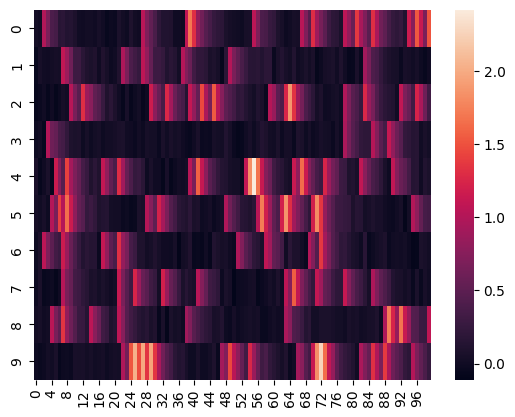

In [137]:
sns.heatmap((F @ X)[:, :100])

<Axes: >

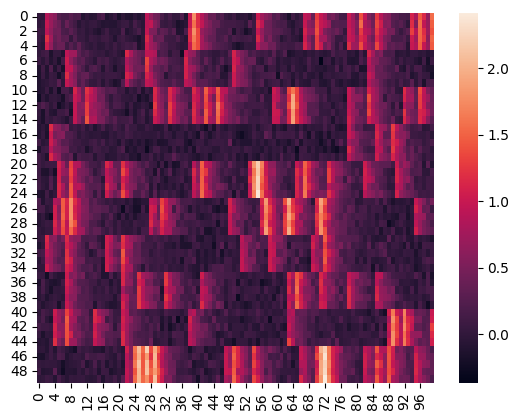

In [151]:
# sort X so rows correspond to Y
sns.heatmap(X[F.argmax(axis=0).argsort(), :100])

<Axes: >

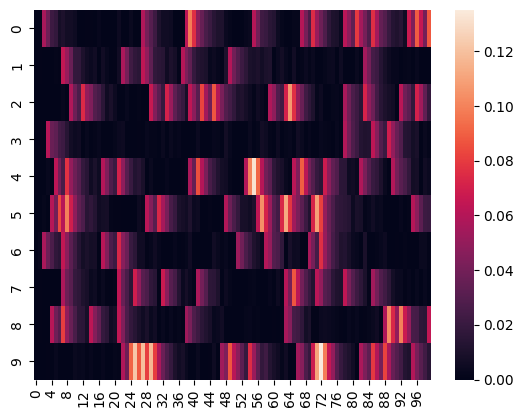

In [149]:
sns.heatmap(Y[:, :100])

In [119]:
def update_weight(W, M, x_t, y_t, y_hat):
    """ Update weight matrix of W and M.
    Equation (8) in the original paper.
    """
    y_dim = y_t.shape[0]
    y_hat += (y_t * y_t)
    
    # (3,1) x (1,2) = (3,2)
    dW = y_t[:,np.newaxis].dot( x_t[np.newaxis,:] - (W.T.dot(y_t[:,np.newaxis])).T)
    #dW = dW / y_hat[:,np.newaxis]
    # (3, 2)
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            W[i] += (dW[i] / y_hat[i])
    
    # (3,1) x (1,3) = (3,3)
    dM = y_t[:,np.newaxis].dot( y_t[np.newaxis,:] - (M.T.dot(y_t[:,np.newaxis])).T)
    #dM = dM / y_hat[:,np.newaxis]
    
    # Set diagonal elements to zero
    for i in range(M.shape[0]):
        dM[i,i] = 0.0
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            M[i] += (dM[i] / y_hat[i])

In [120]:
def adjust_y_i(y_t, x_t, y_index, lambd=0.5):
    """ If the node in y_t is not active previously, adjust it.
    Equation (5) in the original paper.
    """
    # y_t = (3,)
    # x_t = (2,)
    
    y_dim = y_t.shape[0]
    
    # Calculate squree L2 norm of x_t
    x_norm_sq = x_t.dot(x_t)    
    y_t_sqs = y_t * y_t # (3,)
    
    y_t_adj = np.empty_like(y_t)
    
    d_i = x_norm_sq - (np.sum(y_t_sqs) - y_t_sqs[y_index])
    d_i_sq = d_i * d_i
    if d_i_sq <= lambd:
        return 0.0
    else:
        if d_i < 0.0:
            print("d_i was negative: {}".format(d_i))
            d_i = 0.0
    return np.sqrt(d_i)

In [121]:
W_init = W.copy()
M_init = M.copy()

In [122]:
np.linalg.eigvals(M)

array([0.91258808, 0.32541797, 0.24755094])

In [123]:
from qpsolvers import solve_qp

In [124]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [125]:
x_dim = X.shape[0]
T = X.shape[1]

y_dim = k

# Active set {i}
active_i_s = []
active_counts = np.zeros([y_dim], dtype=np.int32)

# Iteration count for convergence
max_iteration = 100

y_t_sum = np.zeros([y_dim])
y_hat = np.zeros([y_dim]) # 3

clusters = []

for t in tqdm(range(5000)):
    # Get one input sample x_t
    x_t = X[:, t].copy() # (2,)
    
    # Zero initialze y_t
    # y_t = np.zeros(y_dim)
    y_t = solve_yt(x_t, W, M, k=k)
    # for i in range(k):
    #     # If 'i' is in the active set {i}
    #     for it in range(max_iteration):
    #         y_t_previous = y_t.copy()
    #         y_t_i = (W[i]  @ x_t) - (M[i] @ y_t_previous)
            
    #         y_t[i] = max(y_t_i, 0)
            
    #         if y_t[i] - y_t_previous[i] < 1e-5:
    #             break
    
    # for i in range(y_dim):
    #     if active_counts[i] == 0:
    #         y_t[i] = adjust_y_i(y_t, x_t, i)
                
    # for i in range(y_dim):
    #     if y_t[i] != 0.0:
    #         active_counts[i] += 1
            
    # for i in range(y_dim):
    #     if (i not in active_i_s) and active_counts[i] > 0:
    #         active_i_s.append(i)

    # update_weight(W, M, x_t, y_t, y_hat)
    
    clusters.append(y_t)
    
Y = np.vstack(clusters)

  0%|          | 0/5000 [00:00<?, ?it/s]

<Axes: >

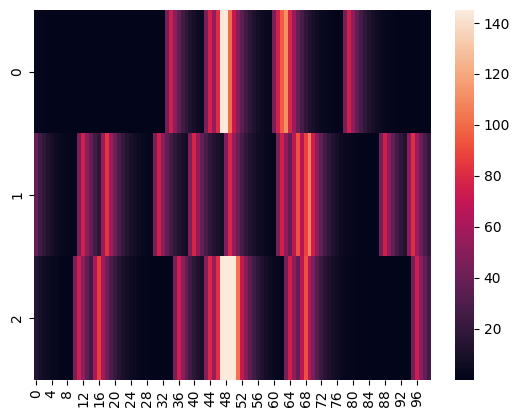

In [126]:
sns.heatmap(Y.T[:, 2500:2600])

<Axes: >

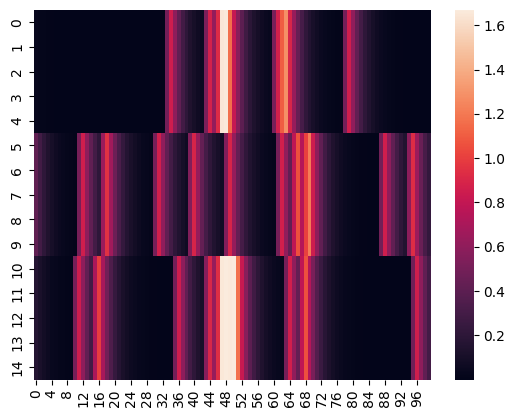

In [127]:
sns.heatmap(X[:, 2500:2600])

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
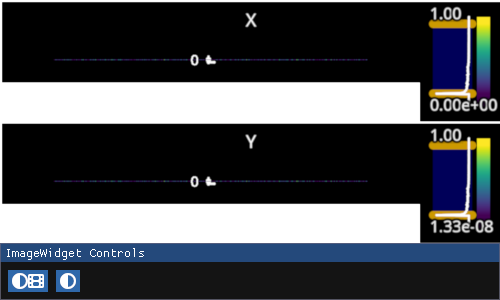

In [98]:
fpl.ImageWidget([X[::5], Y.T], names=["X", "Y"], cmap="viridis", figure_shape=(2, 1)).show()

In [88]:
Y.shape

(5000, 3)

In [89]:
YTY = Y @ Y.T

In [90]:
YTY.shape

(5000, 5000)

In [92]:
XTX = X.T @ X

In [95]:
np.linalg.norm(XTX - YTY, ord="fro") / np.linalg.norm(XTX)

np.float64(0.7997509817668569)

<Axes: >

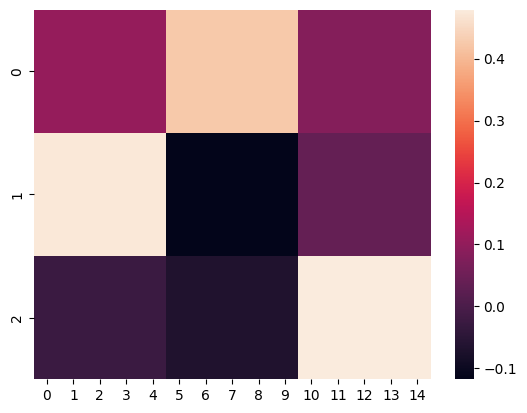

In [774]:
sns.heatmap(W)

<Axes: >

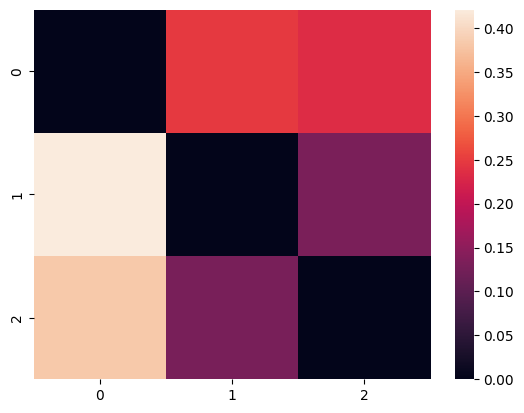

In [775]:
sns.heatmap(M)

In [776]:
np.linalg.eigvals(M)

array([ 0.51003918, -0.38072033, -0.12931885])

<Axes: >

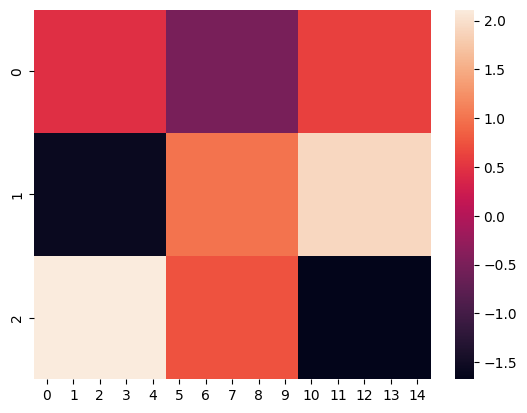

In [777]:
sns.heatmap(np.linalg.inv(M) @ W)